In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [5]:
def getMcRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [6]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [7]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df = applyCut(df, 'pts>15 and bs!=-9 and bs!=0')

In [8]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']
df_pythia= applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'pts>15 and bs!=-9 and bs!=0 and reject<=0 and rejects<=0')

In [9]:
df_pythia = applyCut(df_pythia, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [10]:
w_array = np.unique(df_pythia['w'])

In [11]:
df_pythia_pts_array = [ df_pythia[(df_pythia.pts>20) & (df_pythia.pts<25)],\
                       df_pythia[(df_pythia.pts>25) & (df_pythia.pts<30)],\
                       df_pythia[(df_pythia.pts>30) & (df_pythia.pts<40)] ]

In [12]:
rc_pythia_bs_vs_pts_array = []
rc_err_pythia_bs_vs_pts_array = []
for i in range(0, len(df_pythia_pts_array)):
    rc_pythia_bs_vs_pts_array.append(getMcRcAndErr(df_pythia_pts_array[i], 'bs')[0])
    rc_err_pythia_bs_vs_pts_array.append(getMcRcAndErr(df_pythia_pts_array[i], 'bs')[1])

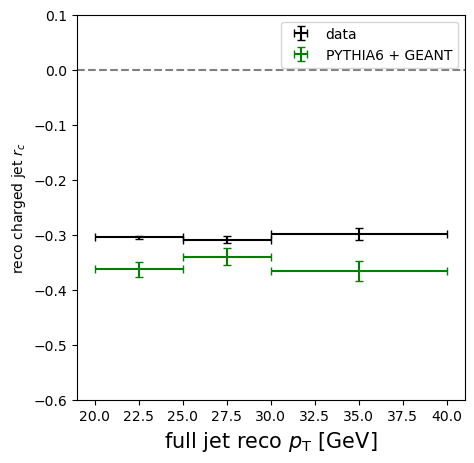

In [17]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], [data_rc_20, data_rc_25, data_rc_30], xerr=[2.5, 2.5, 5], yerr=[data_rc_err_20, data_rc_err_25, data_rc_err_30], capsize=3, ls='none', label='data', color='k')
plt.errorbar([22.5, 27.5, 35], rc_pythia_bs_vs_pts_array, xerr=[2.5, 2.5, 5], yerr=rc_err_pythia_bs_vs_pts_array, capsize=3, ls='none', label='PYTHIA6 + GEANT', color='g')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [45]:
df_20 = applyCut(df, '20 < pts < 25')
df_25 = applyCut(df, '25 < pts < 30')
df_30 = applyCut(df, '30 < pts < 35')
df_35 = applyCut(df, '35 < pts < 40')

In [46]:
data_rc_20, data_rc_err_20 = getRcAndErr(df_20, 'bs')
data_rc_25, data_rc_err_25 = getRcAndErr(df_25, 'bs')
data_rc_30, data_rc_err_30 = getRcAndErr(df_30, 'bs')
data_rc_35, data_rc_err_35 = getRcAndErr(df_35, 'bs')

In [47]:
df_pythia_pts_array = [ df_pythia[(df_pythia.pts>20) & (df_pythia.pts<25)],\
                       df_pythia[(df_pythia.pts>25) & (df_pythia.pts<30)],\
                       df_pythia[(df_pythia.pts>30) & (df_pythia.pts<35)],\
                       df_pythia[(df_pythia.pts>35) & (df_pythia.pts<40)] ]

In [48]:
rc_pythia_bs_vs_pts_array = []
rc_err_pythia_bs_vs_pts_array = []
for i in range(0, len(df_pythia_pts_array)):
    rc_pythia_bs_vs_pts_array.append(getMcRcAndErr(df_pythia_pts_array[i], 'bs')[0])
    rc_err_pythia_bs_vs_pts_array.append(getMcRcAndErr(df_pythia_pts_array[i], 'bs')[1])

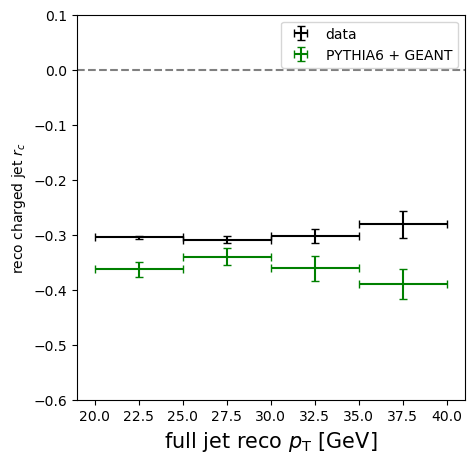

In [49]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 32.5, 37.5], [data_rc_20, data_rc_25, data_rc_30, data_rc_35], xerr=[2.5, 2.5, 2.5, 2.5], yerr=[data_rc_err_20, data_rc_err_25, data_rc_err_30, data_rc_err_35], capsize=3, ls='none', label='data', color='k')
plt.errorbar([22.5, 27.5, 32.5, 37.5], rc_pythia_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 2.5], yerr=rc_err_pythia_bs_vs_pts_array, capsize=3, ls='none', label='PYTHIA6 + GEANT', color='g')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [22]:
df_pythia_20 = applyCut(df_pythia, '20 < pts < 25')
df_pythia_25 = applyCut(df_pythia, '25 < pts < 30')
df_pythia_30 = applyCut(df_pythia, '30 < pts < 40')

In [20]:
ob = 'b'
range_low = -1.
range_high = 1.2
bins = 5

In [21]:
y_rec_20,yerr_rec_20,x = calc_hist(df_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_25,yerr_rec_25,x = calc_hist(df_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_30,yerr_rec_30,x = calc_hist(df_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))

In [38]:
y_rec_pythia_20,yerr_rec_pythia_20,x = calc_hist(df_pythia_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_pythia_20['w'])
y_rec_pythia_25,yerr_rec_pythia_25,x = calc_hist(df_pythia_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_pythia_25['w'])
y_rec_pythia_30,yerr_rec_pythia_30,x = calc_hist(df_pythia_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_pythia_30['w'])

([], [])

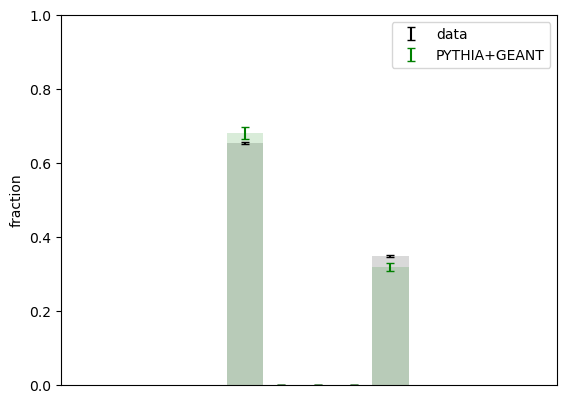

In [39]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.hist(df_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=np.ones(df_20.shape[0])/(df_20.shape[0]), color='k', alpha=0.15)
plt.hist(df_pythia_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_pythia_20['w']/sum(df_pythia_20['w']), color='g', alpha=0.15)
plt.errorbar(x, y_rec_20/sum(y_rec_20), yerr=yerr_rec_20/sum(y_rec_20), capsize=3, color='k', label='data', ls='none')
plt.errorbar(x, y_rec_pythia_20/sum(y_rec_pythia_20), yerr=yerr_rec_pythia_20/sum(y_rec_pythia_20), capsize=3, color='g', label='PYTHIA+GEANT', ls='none')
plt.legend()
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-3,3)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

([], [])

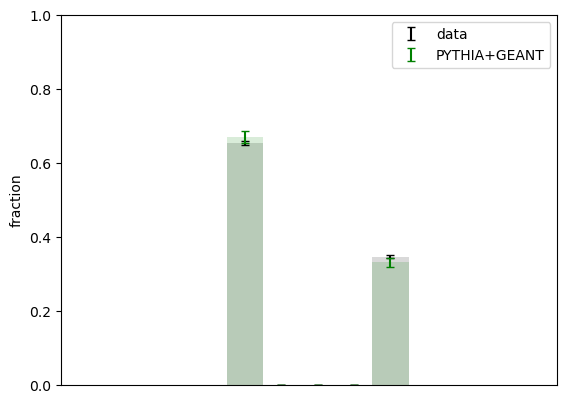

In [40]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.hist(df_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=np.ones(df_25.shape[0])/(df_25.shape[0]), color='k', alpha=0.15)
plt.hist(df_pythia_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_pythia_25['w']/sum(df_pythia_25['w']), color='g', alpha=0.15)
plt.errorbar(x, y_rec_25/sum(y_rec_25), yerr=yerr_rec_25/sum(y_rec_25), capsize=3, color='k', label='data', ls='none')
plt.errorbar(x, y_rec_pythia_25/sum(y_rec_pythia_25), yerr=yerr_rec_pythia_25/sum(y_rec_pythia_25), capsize=3, color='g', label='PYTHIA+GEANT', ls='none')
plt.legend()
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-3,3)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

([], [])

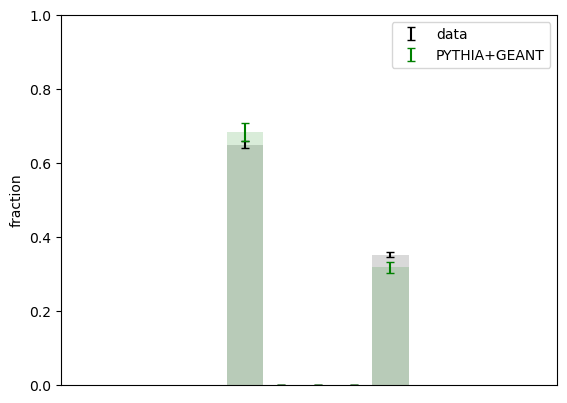

In [41]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.hist(df_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=np.ones(df_30.shape[0])/(df_30.shape[0]), color='k', alpha=0.15)
plt.hist(df_pythia_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_pythia_30['w']/sum(df_pythia_30['w']), color='g', alpha=0.15)
plt.errorbar(x, y_rec_30/sum(y_rec_30), yerr=yerr_rec_30/sum(y_rec_30), capsize=3, color='k', label='data', ls='none')
plt.errorbar(x, y_rec_pythia_30/sum(y_rec_pythia_30), yerr=yerr_rec_pythia_30/sum(y_rec_pythia_30), capsize=3, color='g', label='PYTHIA+GEANT', ls='none')
plt.legend()
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-3,3)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

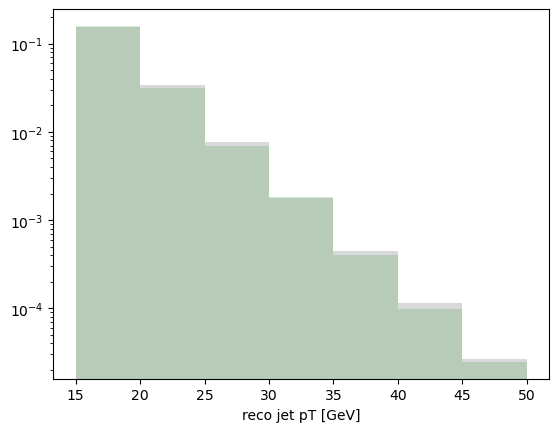

In [44]:
plt.hist(df['pts'], color='k', alpha=0.15, bins=np.arange(15,55,5), density=True)
plt.hist(df_pythia['pts'], weights=df_pythia['w'], color='g', alpha=0.15, bins=np.arange(15,55,5), density=True)
plt.xlabel('reco jet pT [GeV]')
plt.yscale('log')